In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp12: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
np.random.seed(12); tf.random.set_seed(12)
(xtr,ytr),(xte,yte)=tf.keras.datasets.cifar10.load_data()
xtr=xtr[:12000].astype("float32")/255; ytr=ytr[:12000].ravel()
xte=xte[:2500].astype("float32")/255; yte=yte[:2500].ravel()
rows=[]
for conv_layers in [2,3,4]:
  for kernel in [3,5]:
    for pooling in ["max","average"]:
      inp=tf.keras.Input((32,32,3)); x=inp
      for i in range(conv_layers):
        x=tf.keras.layers.Conv2D(16*(2**min(i,2)),kernel,padding="same",activation="relu")(x)
        if i%2==1: x=(tf.keras.layers.MaxPooling2D()(x) if pooling=="max" else tf.keras.layers.AveragePooling2D()(x))
      x=tf.keras.layers.GlobalAveragePooling2D()(x); out=tf.keras.layers.Dense(10,activation="softmax")(x)
      m=tf.keras.Model(inp,out); m.compile(optimizer=tf.keras.optimizers.Adam(.001),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
      start=time.time(); m.fit(xtr,ytr,epochs=2,batch_size=64,validation_split=.1,verbose=0); elapsed=time.time()-start
      acc=m.evaluate(xte,yte,verbose=0)[1]
      rows.append([conv_layers,kernel,pooling,m.count_params(),round(acc,4),round(elapsed,2)])
res=pd.DataFrame(rows,columns=["Conv layers","Filter","Pooling","Parameters","Test accuracy","Training seconds"])
print(res.to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(12,4)); ax[0].bar(range(len(res)),res["Test accuracy"]); ax[0].set_title("Accuracy by configuration"); ax[1].bar(range(len(res)),res["Training seconds"]); ax[1].set_title("Training time"); plt.tight_layout(); plt.show()
print("Best configuration:\n",res.iloc[res["Test accuracy"].argmax()].to_string())

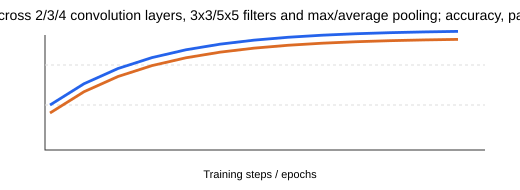

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.